In [1]:
import numpy as np
import seaborn as sns
from sklearn.svm import SVC
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.datasets import make_regression, make_classification
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier

In [2]:
# Función de utilidad para graficar modelos de regresión
def plot_regression_models(models, X_train, y_train, X_test, y_test, X_plot, y_true_fn, title_prefix):
    fig, axs = plt.subplots(3, 2, figsize=(16, 18))
    axs = axs.ravel()

    for i, (title, model) in enumerate(models):
        model.fit(X_train, y_train)
        y_pred = model.predict(X_plot)

        axs[i].scatter(X_train, y_train, color="blue", label="Entrenamiento", alpha=0.6)
        axs[i].scatter(X_test, y_test, color="red", label="Evaluación", alpha=0.6)
        axs[i].plot(X_plot, y_true_fn(X_plot.ravel()), color="green", linestyle="dashed", label="Función real")
        axs[i].plot(X_plot, y_pred, color="black", label="Modelo")
        axs[i].set_title(f"{title_prefix} {title}")
        axs[i].legend()
        axs[i].set_ylim(min(y_train.min(), y_test.min()) - 1, max(y_train.max(), y_test.max()) + 1)

    axs[-1].axis('off')
    plt.tight_layout()
    plt.show()

In [3]:
# Función de utilidad para graficar modelos de clasificación
def plot_classification_models(models, X_train, y_train, grid, xx, yy, title_prefix):
    fig, axs = plt.subplots(3, 2, figsize=(15, 18))
    axs = axs.ravel()

    for i, (title, model) in enumerate(models):
        model.fit(X_train, y_train)
        Z = model.predict(grid).reshape(xx.shape)
        axs[i].contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
        sns.scatterplot(x=X_train[:, 0], y=X_train[:, 1], hue=y_train, ax=axs[i],
                        palette="coolwarm", s=30, edgecolor="k", legend=False)
        axs[i].set_title(f"{title_prefix} {title}")
        axs[i].set_xlim(xx.min(), xx.max())
        axs[i].set_ylim(yy.min(), yy.max())

    axs[-1].axis("off")
    plt.tight_layout()
    plt.show()

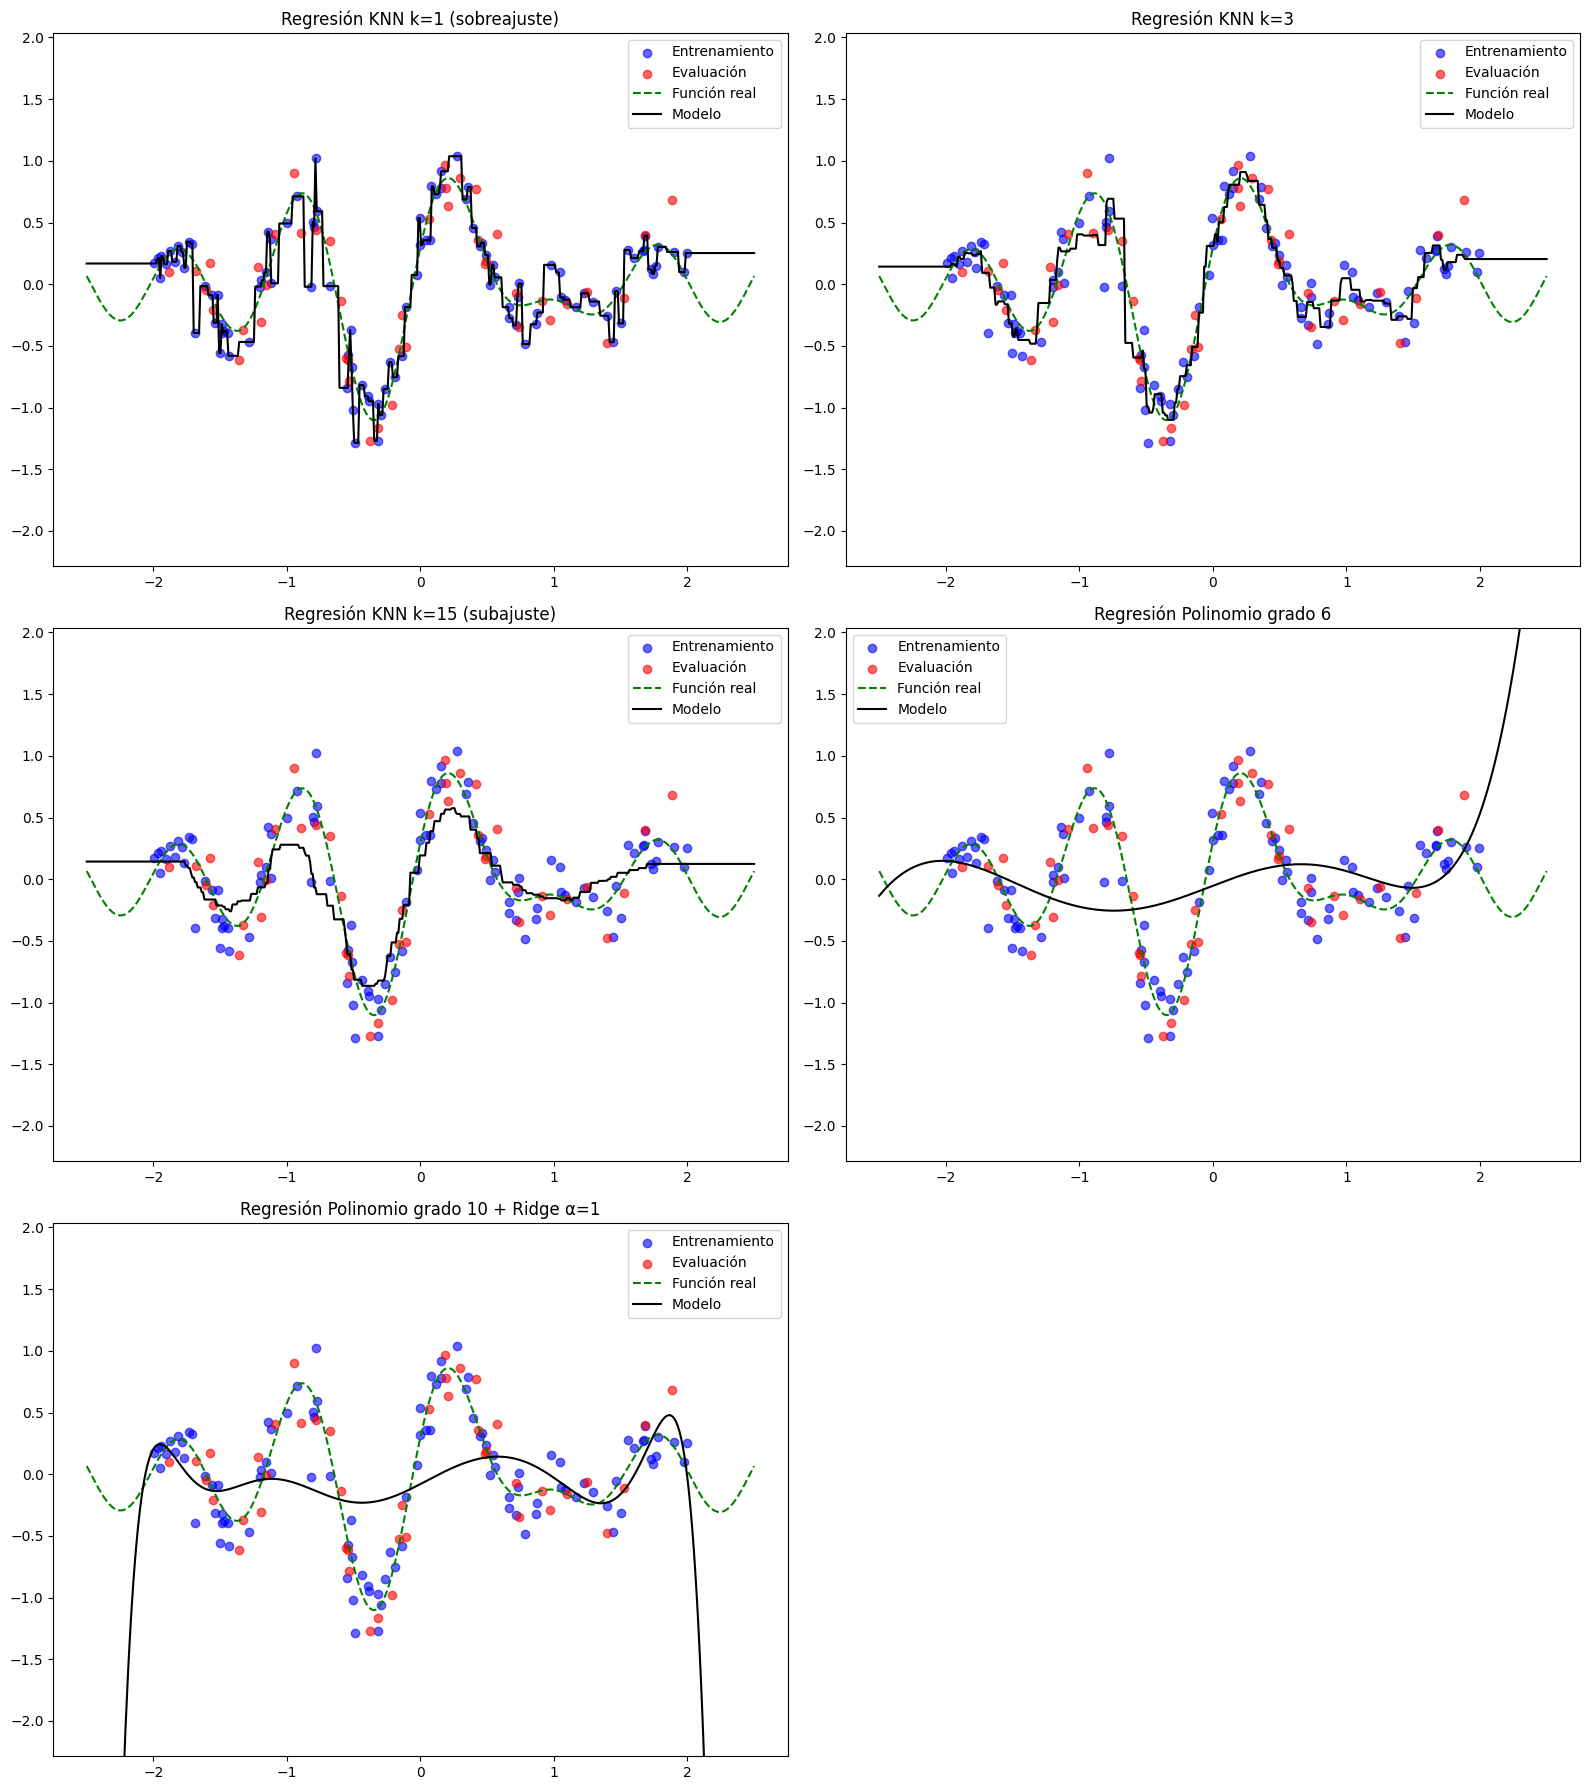

In [4]:
# ---------------------------
# Nuevos ejemplos de REGRESIÓN
# ---------------------------
def complex_regression_function(x):
    return np.sin(5 * x) * np.exp(-x**2) + 0.3 * np.cos(7 * x)

# Datos
np.random.seed(15)
X_r = np.sort(np.random.rand(150) * 4 - 2)
y_r_true = complex_regression_function(X_r)
y_r = y_r_true + np.random.normal(scale=0.2, size=X_r.shape)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_r.reshape(-1, 1), y_r, test_size=0.3, random_state=1)
Xr_plot = np.linspace(-2.5, 2.5, 500).reshape(-1, 1)

# Modelos de regresión adicionales
regression_models = [
    ("KNN k=1 (sobreajuste)", KNeighborsRegressor(n_neighbors=1)),
    ("KNN k=3", KNeighborsRegressor(n_neighbors=3)),
    ("KNN k=15 (subajuste)", KNeighborsRegressor(n_neighbors=15)),
    ("Polinomio grado 6", make_pipeline(PolynomialFeatures(6), LinearRegression())),
    ("Polinomio grado 10 + Ridge α=1", make_pipeline(PolynomialFeatures(10), Ridge(alpha=1))),
]

# Graficar regresión
plot_regression_models(regression_models, Xr_train, yr_train, Xr_test, yr_test, Xr_plot, complex_regression_function, "Regresión")

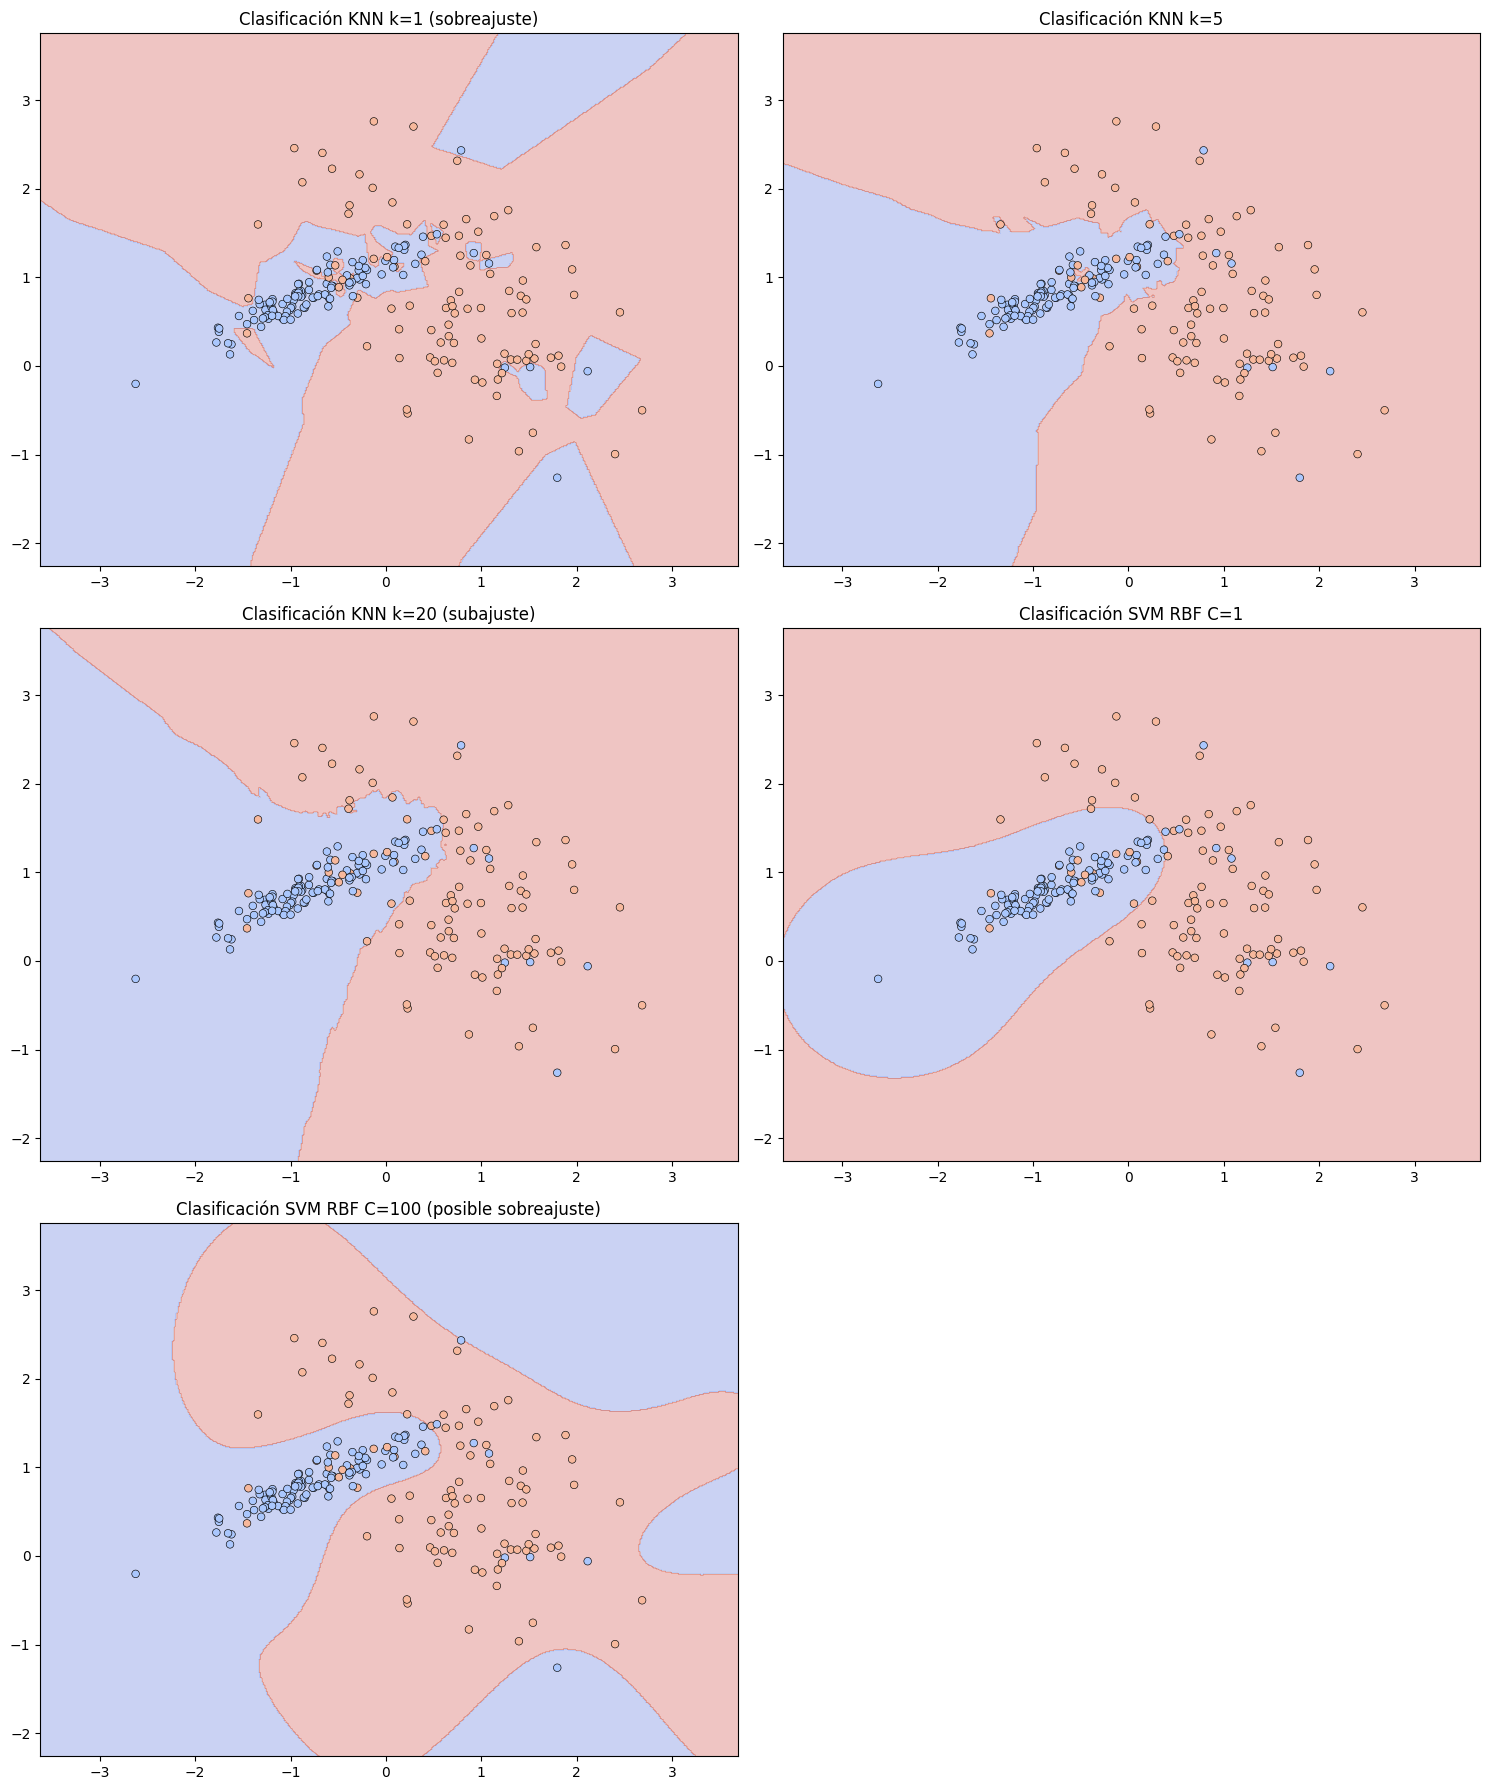

In [5]:
# ---------------------------
# Nuevos ejemplos de CLASIFICACIÓN
# ---------------------------

# Dataset sintético más complejo
X_c, y_c = make_classification(n_samples=300, n_features=2, n_redundant=0, n_clusters_per_class=1,
                               class_sep=0.8, flip_y=0.1, random_state=42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_c, y_c, test_size=0.3, random_state=42)

xxc, yyc = np.meshgrid(np.linspace(X_c[:, 0].min()-1, X_c[:, 0].max()+1, 500),
                       np.linspace(X_c[:, 1].min()-1, X_c[:, 1].max()+1, 500))
gridc = np.c_[xxc.ravel(), yyc.ravel()]

# Modelos de clasificación adicionales
classification_models = [
    ("KNN k=1 (sobreajuste)", KNeighborsClassifier(n_neighbors=1)),
    ("KNN k=5", KNeighborsClassifier(n_neighbors=5)),
    ("KNN k=20 (subajuste)", KNeighborsClassifier(n_neighbors=20)),
    ("SVM RBF C=1", SVC(kernel="rbf", C=1)),
    ("SVM RBF C=100 (posible sobreajuste)", SVC(kernel="rbf", C=100)),
]

# Graficar clasificación
plot_classification_models(classification_models, Xc_train, yc_train, gridc, xxc, yyc, "Clasificación")